<a href="https://colab.research.google.com/github/Ashwini9713/fundamentals-of-ML/blob/main/exp20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

,TV,Radio,Newspaper,Sales
0,232.412859,38.870242,30.192739,22.746042
1,132.224653,48.591321,91.844190,17.895529
2,257.720778,25.037059,78.129404,19.977787
3,209.513041,7.194875,11.058841,10.191289
4,29.159027,0.696814,99.703466,2.809733


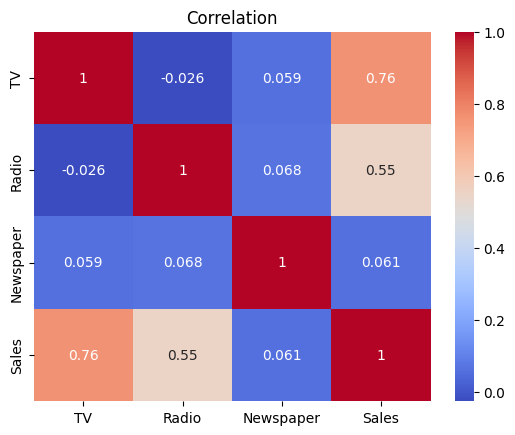

MAE : 1.222282457467583
RMSE: 1.4863988373593089
R2  : 0.9097653630935272


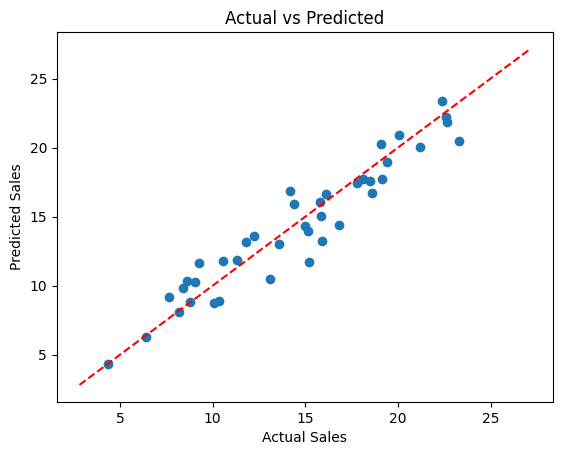

Predicted future sales: 17.84


In [1]:
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# from google.colab import files; files.upload()   # uncomment to upload advertising.csv
if os.path.exists("advertising.csv"):
    df = pd.read_csv("advertising.csv")
    df = df.loc[:, ~df.columns.str.contains("Unnamed")]
else:
    rng = np.random.default_rng(42)
    n = 200
    df = pd.DataFrame({"TV": rng.uniform(1, 300, n),
                       "Radio": rng.uniform(0, 50, n),
                       "Newspaper": rng.uniform(0, 100, n)})
    df["Sales"] = 3 + 0.045*df.TV + 0.19*df.Radio + 0.001*df.Newspaper + rng.normal(0, 1.5, n)

display(df.head())
sns.heatmap(df.corr(), annot=True, cmap="coolwarm"); plt.title("Correlation"); plt.show()

X = df[["TV", "Radio", "Newspaper"]]; y = df["Sales"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

lr = LinearRegression().fit(X_train, y_train)
pred = lr.predict(X_test)

print("MAE :", mean_absolute_error(y_test, pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred)))
print("R2  :", r2_score(y_test, pred))

plt.scatter(y_test, pred); plt.plot([y.min(), y.max()], [y.min(), y.max()], "r--")
plt.xlabel("Actual Sales"); plt.ylabel("Predicted Sales"); plt.title("Actual vs Predicted"); plt.show()

# Future sales for a planned ad budget
future = pd.DataFrame([[200, 30, 20]], columns=["TV", "Radio", "Newspaper"])
print("Predicted future sales:", round(lr.predict(future)[0], 2))